# NEST Simulator balanced network tutorial

The _Brunel_ or _balanced_ network is a widely used benchmark model in computational neuroscience introduced by [Nicolas Brunel (2000)](https://link.springer.com/article/10.1023/A:1008925309027). It is a spiking model that captures the balance between excitation and inhibition in large-scale cortical circuits: a tightly coupled, rapid temporal correlation between excitatory inputs (primarily glutamatergic, from pyramidal neurons) and inhibitory inputs (primarily GABAergic, from various interneuron subtypes). It prevents pathological neural activity (such as epileptic seizures) while maintaining the dynamic range required for information processing. Essentially, E/I balance ensures that the cortex is critically poised: excited enough to be highly responsive to subtle inputs, yet inhibited enough to maintain stability and prevent network-wide saturation.

<center>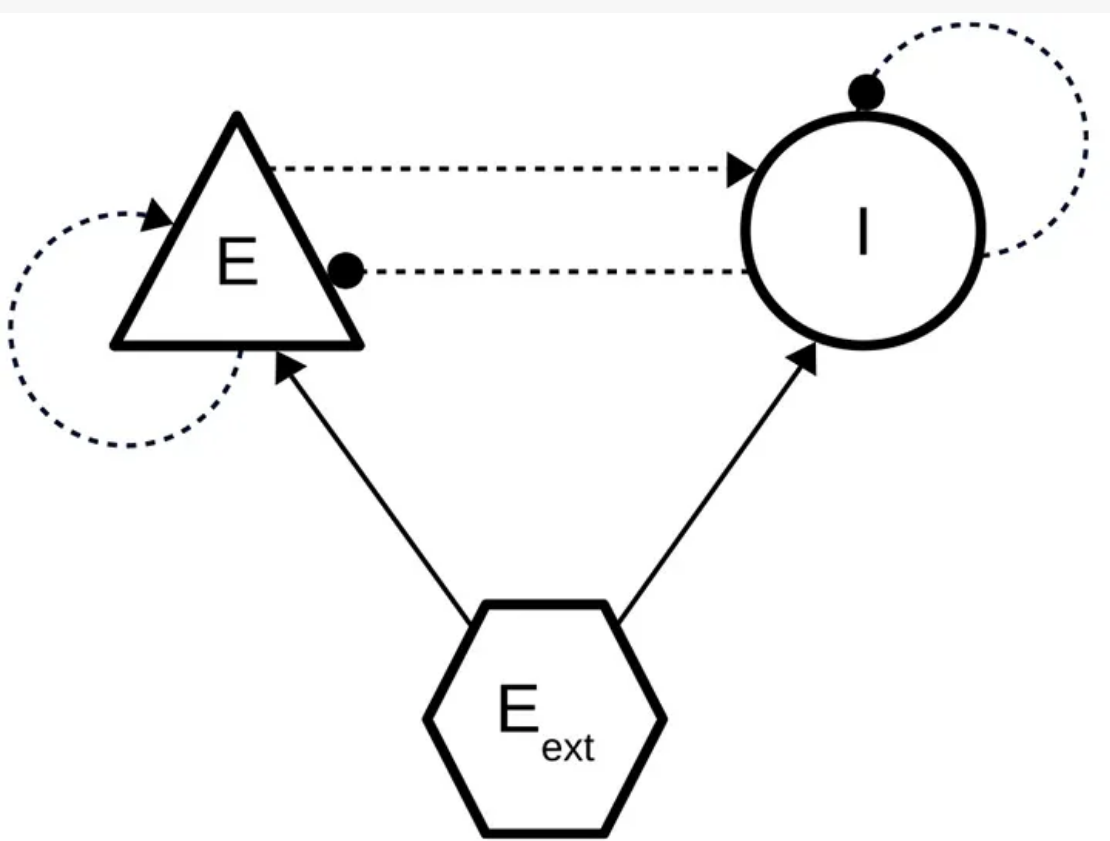</center>

The network consists of:
- Two neuronal populations: one excitatory and one inhibitory, both consisting of integrate-and-fire neurons, where an incoming spike causes an instantaneous jump in the membrane potential (hence the name "delta", referring to the Dirac delta function).
- Sparse, random connectivity between neurons.

The E/I balance in the network is achieved by means of both the number of excitatory to inhibitory neurons and the strength of the connections. The parameter $g$ defines the ratio between the excitatory postsynaptic response and inhibitory postsynaptic response; higher $g$ means the network becomes more inhibition-dominated. The other central parameter in the balanced network is the strength of the external input drive. Because it is only practical to simulate networks that are a lot smaller than biological cortical networks, the part of the input to the network that would normally come from recurrent connections now needs to be supplied by an external source. For this, we use independently generated Poissonian spike trains. The strength of the external input can be scaled by the parameter $\eta$.

Let's begin with an inhibition-dominated network and a moderate external drive:

In [1]:
g = 6      # ratio between inhibition and excitation
eta = 4    # strength of the external drive

To set up the network, let's begin by importing the necessary packages:

In [2]:
import numpy as np
import nest
import matplotlib.pyplot as plt
import elephant
from elephant.statistics import isi, cv
from elephant.conversion import BinnedSpikeTrain
from neo.core import SpikeTrain
from quantities import s
from elephant.spike_train_correlation import corrcoef
import numpy as np
import pandas as pd
import seaborn as sns

nest.local_num_threads = 4    # EBRAINS VM can use multi-threading!
nest.set_verbosity('M_WARNING')


              -- N E S T --
  Copyright (C) 2004 The NEST Initiative

 Version: 3.9.0
 Built: Nov  4 2025 17:52:39

 This program is provided AS IS and comes with
 NO WARRANTY. See the file LICENSE for details.

 Problems or suggestions?
   Visit https://www.nest-simulator.org

 Type 'nest.help()' to find out more about NEST.



## Setting up the neuron populations

First, we will set up the populations in the network. The more neurons are in the simulated network, the more closely it approximates the real biological brain. However, large networks take a long time to simulate and require a lot of RAM. Here, we choose to use about $10^5$ neurons, 1/5th of which is inhibitory, and the remainder of which is excitatory.

In [3]:
order = 2000
NE = 4 * order  # number of excitatory neurons
NI = 1 * order  # number of inhibitory neurons

N_neurons = NE + NI  # number of neurons in total

We will use the simple "iaf_psc_delta" neuron model and normalise the parameters for simplicity (for instance, rather than setting the leakage potential to -70 mV, we set it to 0.

In [4]:
neuron_model_type = "iaf_psc_delta"

tauMem = 20.0    # time constant of membrane potential in ms
theta = 20.0     # membrane threshold potential in mV
neuron_params = {"C_m": 1.0,
                 "tau_m": tauMem,
                 "t_ref": 2.0,
                 "E_L": 0.0,
                 "V_reset": 0.0,
                 "V_m": 0.0,
                 "V_th": theta}

# create the excitatory and inhibitory
nodes_ex = nest.Create(neuron_model_type, NE, params=neuron_params)
nodes_in = nest.Create(neuron_model_type, NI, params=neuron_params)

## Setting up the external input population

To set up the external Poisson generators, we need to scale the rate of the generators by the size of the postsynaptic response of a connection. Therefore, we first define the absolute strength of excitatory connections in the network as the parameter $J$, and the connection probability as $\varepsilon$ (see below under "Connecting the network" for more details about the connectivity structure and how it relates to $\varepsilon$).

In [5]:
J = 0.1  # postsynaptic amplitude in mV

epsilon = 0.1  # connection probability

CE = int(epsilon * NE)  # average number of excitatory synapses per neuron
CI = int(epsilon * NI)  # average number of inhibitory synapses per neuron

nu_th = theta / (J * CE * tauMem)
nu_ex = eta * nu_th
p_rate = 1000.0 * nu_ex * CE

noise = nest.Create("poisson_generator", params={"rate": p_rate})

## Setting up recording devices

In order to visualise the membrane potential of a neuron in the E/I balanced regime, we measure $V_\text{m}$ from two random neurons, one from the excitatory and one from the inhibitory population.

We will also record spikes generated by the populations.

In [6]:
# Create spike recorder
spike_recorder = nest.Create("spike_recorder")
nest.Connect(nodes_ex, spike_recorder)
nest.Connect(nodes_in, spike_recorder)
    
# create multimeter record of V_m
membrane_potential_recorder = nest.Create("multimeter", {"record_from": ["V_m"]})
nest.Connect(membrane_potential_recorder, nodes_ex[0])
nest.Connect(membrane_potential_recorder, nodes_in[0])
    

## Connecting the network

Now that we have created the neuron population and their corresponding inputs, we need to properly connect the neurons to each other and to their respective inputs. To do this, we use the following command: ``nest.Connect(source_pop, target_pop, conn_dict, syn_dict)``.

This function requires the specification of source and target nodes (single nodes or populations of nodes); one dictionary describing the connection rule, and one dictionary defining the synaptic parameters.

The dictionary ``conn_dict`` contains the specification of the connection rule, which defines how connections are distributed among neurons. Only connection rules that do not require additional parameters can be provided as simple strings. For all other cases, a dictionary must be used to define the rule and its parameters, for example, specifying fixed in-degree or out-degree values.

In this case, we use the **pairwise_bernoulli** rule, with a fixed connection probability of $\varepsilon=.1$. Note that the code also contains alternative connection rules, which are you are invited to experiment with!

The other connection types available in NEST work as follows:

- **One to one**: the $i$-th node in pre is connected to the $i$-th node in post. The pre- and post-synaptic populations have to be of the same size.
- **All to all**: each node in pre is connected to every node in post.
- **Fixed-total-number** : the nodes in pre are randomly connected with the nodes in post such that the total number of connections equals $N$.
- **Fixed_indegree** : the nodes in pre are randomly connected with the nodes in post such that each node in post has a fixed indegree.
- **Fixed_outdegree** : the nodes in pre are randomly connected with the nodes in post such that each node in pre has a fixed outdegree.

These have been implemented following the logic used in NEST (see https://nest-simulator.readthedocs.io/en/stable/synapses/connectivity_concepts.html for more details).

Regarding the synaptic dictionary, we need to specify both the synaptic weight and the synaptic delay. The weight determines the strength of the synaptic connection, i.e., how much influence a presynaptic spike has on the postsynaptic neuron. The delay represents the time interval between the emission of a spike by the presynaptic neuron and its reception by the postsynaptic neuron.

In [7]:
# Connection parameters
J_ex = J          # amplitude of excitatory postsynaptic potential
J_in = -g * J_ex  # amplitude of inhibitory postsynaptic potential

delay = 1.  # synaptic delay in ms

syn_params_ex = {"synapse_model": "static_synapse", "weight": J_ex, "delay": delay}
syn_params_in = {"synapse_model": "static_synapse", "weight": J_in, "delay": delay}

conn_rule = "pairwise_bernoulli"

# create the connections
if conn_rule == "pairwise_bernoulli":
    conn_params_ex = {"rule": "pairwise_bernoulli", "p": epsilon}
    conn_params_in = {"rule": "pairwise_bernoulli", "p": epsilon}
else:
    if conn_rule == "fixed_outdegree":
        conn_params_ex = {"rule": "fixed_outdegree", "outdegree": CE}
        conn_params_in = {"rule": "fixed_outdegree", "outdegree": CI}
    elif conn_rule == "fixed_indegree":
        conn_params_ex = {"rule": "fixed_indegree", "indegree": CE}
        conn_params_in = {"rule": "fixed_indegree", "indegree": CI}
    elif conn_rule == "fixed_total_number":
        conn_params_ex = {"rule": "fixed_total_number", "N": N_E * C_E}
        conn_params_in = {"rule": "fixed_total_number", "N": N_I * C_I}
    
# create recurrent connections in the network
nest.Connect(nodes_ex, nodes_ex + nodes_in, conn_params_ex, syn_params_ex)
nest.Connect(nodes_in, nodes_ex + nodes_in, conn_params_in, syn_params_in)

# Connect external stimulus population
nest.Connect(noise, nodes_ex + nodes_in, syn_spec=syn_params_ex)

print(f"Number of network nodes: {nest.network_size}")
print(f"          connections  : {nest.num_connections}")

Number of network nodes: 10003
          connections  : 10020571


## Running the simulation

Now that the network populations, connectivity and instrumentation are fully set up, we only need to invoke NEST to run the simulation. We set a time resolution of 0.1 ms and simulate for a total time of 500 ms.

In [8]:
simtime = 500.0  # Simulation time in ms
dt = 0.1    # the resolution in ms

nest.Simulate(simtime)

## Data analysis

Now that the simulation is complete, we can grab the data from the recording devices. Let's start by looking at the neuron's membrane potential recordings:

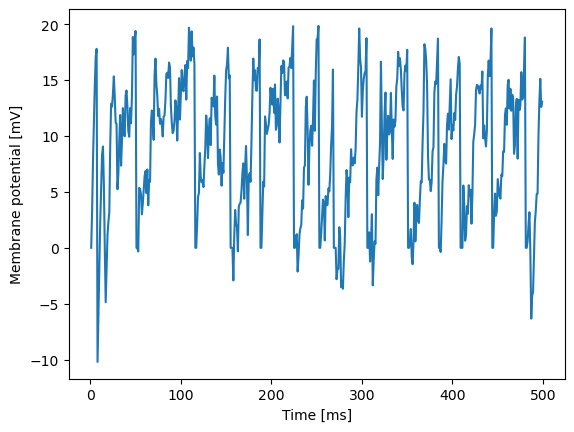

In [9]:
def map_multimeter_to_nodes(multimeter_output, record_label='V_m'):
    """
    Converts NEST multimeter output to a dict mapping node ID to measurements.
    
    Args:
        multimeter_output (dict): The result of nest.GetStatus(multimeter, 'events')[0]
        record_label (str): The name of the recorded variable (e.g., 'V_m', 'g_ex').
        
    Returns:
        dict: {node_id: [measurement_1, measurement_2, ...]}
    """
    events = multimeter_output
    senders = events['senders']
    values = events[record_label]
    
    node_data = {}
    
    for node_id, val in zip(senders, values):
        if node_id not in node_data:
            node_data[node_id] = []
        node_data[node_id].append(val)
        
    return node_data

V_m_converted = map_multimeter_to_nodes(membrane_potential_recorder.events, 'V_m')

t = np.unique(membrane_potential_recorder.events["times"])
V1 = np.array(V_m_converted[nodes_ex[0].global_id])
V2 = np.array(V_m_converted[nodes_in[0].global_id])

plt.figure(1)
plt.plot(t, V1)
plt.xlabel('Time [ms]')
plt.ylabel('Membrane potential [mV]')

plt.figure(2)
plt.plot(t, V2)
plt.xlabel('Time [ms]')
plt.ylabel('Membrane potential [mV]')

plt.draw()
plt.close()

## Spike data analysis

Now we can start with the analysis of spikes coming from the two different populations.

To analyse data we use [elephant](https://elephant.readthedocs.io/). Elephant (Electrophysiology Analysis Toolkit) is an open-source, community centered library for the analysis of electrophysiological data in the Python programming language. The focus of Elephant is on generic analysis functions for spike train data and time series recordings from electrodes, such as membrane voltages.

Before using specialized Elephant functions, we can first obtain a rough estimate of the firing rates of the two populations by simply analyzing the recorded spike data.  

`spike_times` is a list of lists in Python, meaning it is a data structure where each element of the main list is itself a list. 

spike_times[0]=[1,2,3,...] are the spike times of the first recorded neuron, and so on.

In [10]:
node_ids = (nodes_ex + nodes_in).get("global_id")
data = nest.GetStatus(spike_recorder, "events")[0]
senders = data["senders"]
times = data["times"]
spike_times = [times[senders == nid].tolist() for nid in node_ids]

e_count = 0
i_count = 0
e_bound = NE         # number of excitatory neurons
i_bound = NE + NI    # total number of neurons
for i_neur in range(i_bound):
    spikes = spike_times[i_neur]    # spike times of the i_neur‑th neuron
    if len(spikes) != 0:
        if i_neur < e_bound:
            for t in spikes:
                e_count += 1 #counts ex. spikes 
        else:
            for t in spikes:
                i_count += 1 #counts in. spikes 

print(f"The firing rate for excitatory population: {(e_count / (NE * simtime) * 1e3):.2f} Hz")
print(f"The firing rate for inhibitory population: {(i_count / (NI * simtime) * 1e3):.2f} Hz")

The firing rate for excitatory population: 56.76 Hz
The firing rate for inhibitory population: 56.63 Hz


To get a more detailed look, let's mae a raster plot of a subset of inhibitory and excitatory neurons.

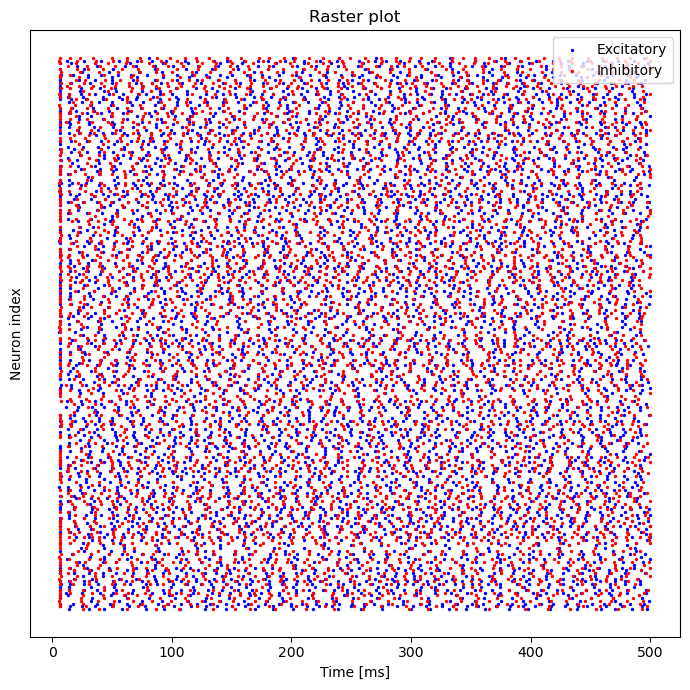

In [11]:
pct_to_plot_in = 0.1        # in. neurons percentage to plot
pct_to_plot_ex = 0.025  # ex. neurons percentage to plot
marker_size = 2

# split ex. and in. data
data_ex = spike_times[:NE]
data_in = spike_times[NE:NE+NI]

N_ex = len(data_ex)
N_in = len(data_in)
num_ex = max(1, int(N_ex * pct_to_plot_ex))
num_in = max(1, int(N_in * pct_to_plot_in))
neurons_ex = np.random.choice(N_ex, size=num_ex, replace=False)
neurons_in = np.random.choice(N_in, size=num_in, replace=False)

plt.figure(figsize=(7, 7))

for local_idx, neuron_id in enumerate(neurons_ex):
    spikes = data_ex[neuron_id]
    if spikes:
        plt.scatter(spikes, [local_idx]*len(spikes), s=marker_size, color='blue', label='Excitatory' if local_idx == 0 else "")

for local_idx, neuron_id in enumerate(neurons_in):
    spikes = data_in[neuron_id]
    if spikes:
        plt.scatter(spikes, [local_idx]*len(spikes), s=marker_size, color='red', label='Inhibitory' if local_idx == 0 else "")

plt.xlabel('Time [ms]')
plt.ylabel('Neuron index')
plt.title(f'Raster plot')
plt.yticks([])
plt.legend()
plt.tight_layout()
plt.show()

## Firing rate distribution

We can analyze the firing rate distribution of the two neuron populations and compare them using a bar plot. To compute the firing rates, we can use the function `elephant.statistics.mean_firing`, which calculates the firing rate from a spike train (i.e., a list of spike times).

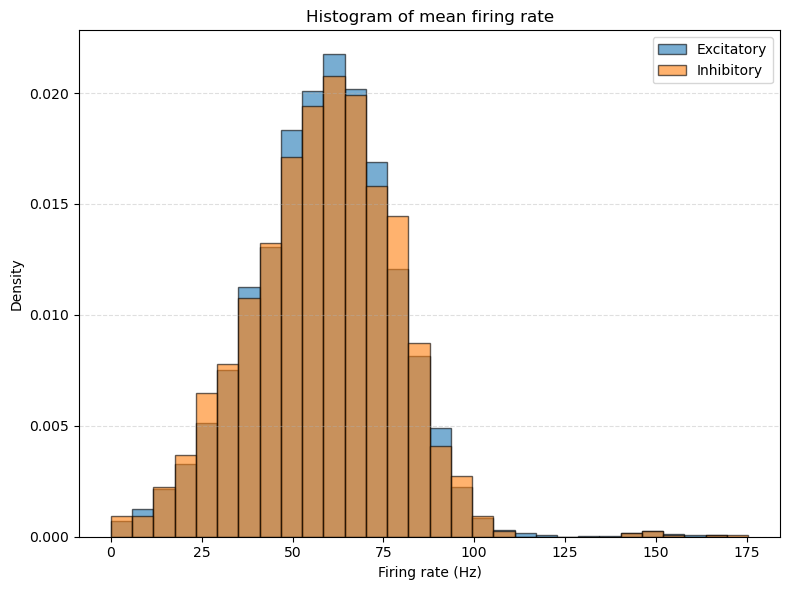

In [12]:
begin = 0
end = 1000  # ms = 1 s


# elephant.statistics.mean_firing rate compute the firing rate starting from a spike train
dist_ex = [1000*elephant.statistics.mean_firing_rate(data_ex[i]) if data_ex[i] else 0 for i in range(NE)]
dist_in = [1000*elephant.statistics.mean_firing_rate(data_in[i]) if data_in[i] else 0 for i in range(NI)]

min_val = min(np.min(dist_ex), np.min(dist_in))
max_val = max(np.max(dist_ex), np.max(dist_in))

bins = np.linspace(min_val, max_val, 31)  

color_ex = '#1f77b4'
color_in = '#ff7f0e'

plt.figure(figsize=(8, 6))

plt.hist(dist_ex, bins=bins, density=True, alpha=0.6, label='Excitatory', color=color_ex, edgecolor='black')
plt.hist(dist_in, bins=bins, density=True, alpha=0.6, label='Inhibitory', color=color_in, edgecolor='black')

plt.title('Histogram of mean firing rate')
plt.xlabel('Firing rate (Hz)')
plt.ylabel('Density')
plt.legend(loc='upper right')
plt.grid(True, axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

## CV ISI PLOT

Now we can plot the CV ISI (Coefficient of variation of interspike intervals) distibutions to have some information about the spike train patterns. High values of CV ISI correspond to irregular or highly variable spike timing, indicating more bursty or random firing patterns. Conversely, low values of CV ISI indicate more regular and periodic spike trains, reflecting consistent firing intervals.

The coefficient of variation of the inter-spike intervals (i.e., CV ISI) is defined as the ratio between the standard deviation and the average of the inter-spike intervals:

$$
\mathrm{CV}_i = \frac{\sqrt{\sum_k \left( \text{ISI}^{(i)}_k - \langle \text{ISI}^{(i)}_k \rangle \right)^2}}{\sum_k \text{ISI}^{(i)}_k}
\tag{4.5}
$$

Given a spike train, the inter-spike interval (ISI) is defined as the time difference between two consecutive spikes. Thus:

$$ \text{ISI}_i(t) = t^{(i)}_{k+1} - t^{(i)}_k $$

Like the firing rate, this is a quantity extracted from a single neuron. Therefore, the **population distribution** is the collection of all $\mathrm{CV}_i$ values computed for each neuron in the population.

Using the Elephant library, we first compute the interspike intervals (ISI) with the `isi` function. Then, by applying the `cv` function to these ISI values, we calculate the coefficient of variation (CV) of the ISI distribution.

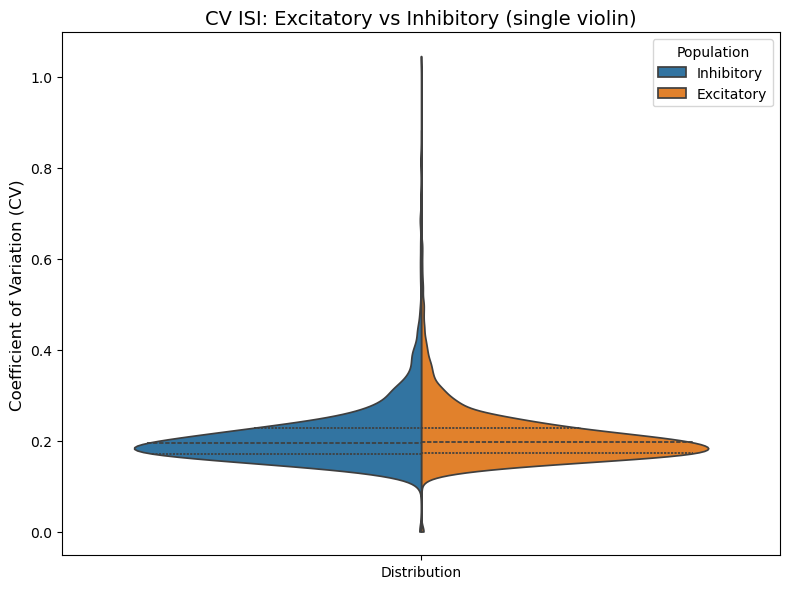

In [13]:
dist_cvisi = []

cvisi_in = [cv(isi(st_row)) for st_row in data_in if len(st_row) > 1]
cvisi_ex = [cv(isi(st_row)) for st_row in data_ex if len(st_row) > 1]

df = pd.DataFrame({
    'CV': np.concatenate([cvisi_in, cvisi_ex]),
    'Population': ['Inhibitory'] * len(cvisi_in) + ['Excitatory'] * len(cvisi_ex),
    'Group': ['Distribution'] * (len(cvisi_in) + len(cvisi_ex))  
})

plt.figure(figsize=(8,6))
sns.violinplot(x='Group', y='CV', hue='Population', data=df, split=True, inner="quartile", bw_method="silverman", gridsize=300, cut=0)
plt.title('CV ISI: Excitatory vs Inhibitory (single violin)', fontsize=14)
plt.ylabel('Coefficient of Variation (CV)', fontsize=12)
plt.xlabel('')
plt.legend(title='Population')
plt.tight_layout()
plt.show()

## Spike train correlations

To compute the Pearson correlation coefficient using Elephant, we first need to convert the spike data into `SpikeTrain` objects, and then into a `BinnedSpikeTrain`, which is a time-binned representation of the spike trains suitable for statistical analysis. We can perform this transformation for both the excitatory and inhibitory populations, and then compare the resulting correlation values using a violin plot.

To properly compute this statistical distribution, spike trains are binned using a time step of 2 ms (i.e., the neuron's refractory time used when simulating the network models), so that at most one spike can occur at each bin. We call **$b_i$** the binned spike train of the neuron *i* and **$\mu_i$** a vector with the same length of $b_i$ having all the entries equal to the average of the binned spike train.

Then, Pearson correlation can be computed as follows:

$$
C[i, j] = \frac{\langle b_i - \mu_i,\ b_j - \mu_j \rangle}{\sqrt{ \langle b_i - \mu_i,\ b_i - \mu_i \rangle \cdot \langle b_j - \mu_j,\ b_j - \mu_j \rangle }}
\tag{1}
$$

where $\langle \cdot,\ \cdot \rangle$ represents a scalar (dot) product.

Considering 200 neurons per population, the result of Equation 1 is a $200 \times 200$ matrix, and the distribution of the pairwise Pearson correlation is formed by the **non-diagonal** entries of the matrix.

We choose 200 neurons to compute the correlation matrix to have a reasonable computation time.

[[0 0 0 ... 0 0 0]
 [1 1 1 ... 0 0 0]
 [1 1 0 ... 0 0 0]
 ...
 [0 1 1 ... 0 0 0]
 [1 0 1 ... 0 0 0]
 [1 1 0 ... 0 0 0]]


/srv/main-spack-instance-2502/ebrains-spack-builds/vendor/spack/var/spack/environments/experimental/.spack-env/view/lib/python3.11/site-packages/numpy/lib/function_base.py:2897: RuntimeWarning:invalid value encountered in divide
/srv/main-spack-instance-2502/ebrains-spack-builds/vendor/spack/var/spack/environments/experimental/.spack-env/view/lib/python3.11/site-packages/numpy/lib/function_base.py:2898: RuntimeWarning:invalid value encountered in divide


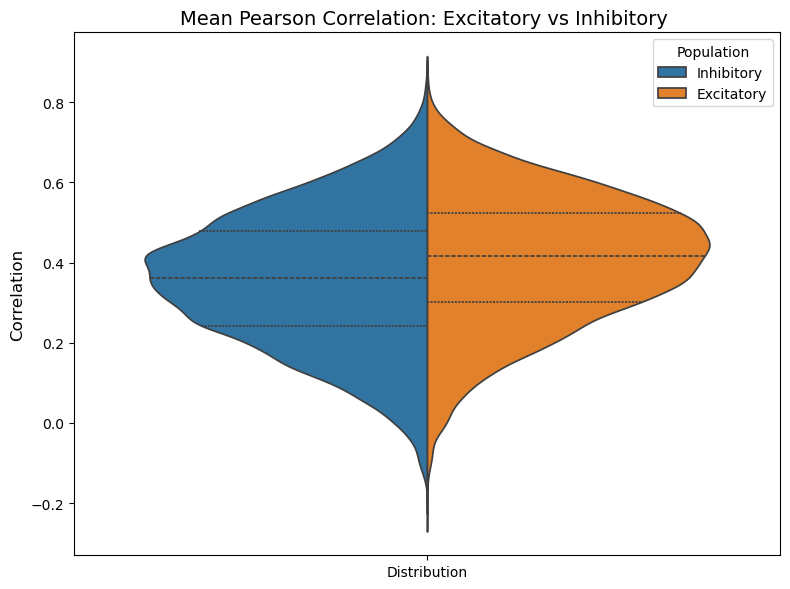

In [14]:
st_list_ex = []
dist_corr_ex= []
st_list_in = []
dist_corr_in= []
matrix_size = 200
spike_time_bin = 0.01

begin = 0.
end = 1000.

# computing correlatin matrix for excitatory neurons
for j in range(matrix_size):
    spike_train = SpikeTrain(np.array(data_ex[j])/1000*s,t_stop=1*s)
    st_list_ex.append(spike_train)

binned_st = BinnedSpikeTrain(st_list_ex, spike_time_bin*s, tolerance=None)
print(binned_st.to_array())

cc_matrix = corrcoef(binned_st)
for j in range(matrix_size):
    for k in range(matrix_size):
            if (j != k and not np.isnan(cc_matrix[j][k])):
                dist_corr_ex.append(cc_matrix[j][k])

# computing correlatin matrix for inhibitory neurons
for j in range(matrix_size):
    spike_train = SpikeTrain(np.array(data_in[j])/1000*s,t_stop=1*s)
    st_list_in.append(spike_train)

binned_st = BinnedSpikeTrain(st_list_in, spike_time_bin*s, tolerance=None)

cc_matrix = corrcoef(binned_st)
for j in range(matrix_size):
    for k in range(matrix_size):
            if (j != k and not np.isnan(cc_matrix[j][k])):
                dist_corr_in.append(cc_matrix[j][k])

# plotting resulting distributions
df = pd.DataFrame({
    'Correlation': np.concatenate([dist_corr_in, dist_corr_ex]),
    'Population': ['Inhibitory'] * len(dist_corr_in) + ['Excitatory'] * len(dist_corr_ex),
    'Group': ['Distribution'] * (len(dist_corr_in) + len(dist_corr_ex))  
})

plt.figure(figsize=(8,6))
sns.violinplot(x='Group', y='Correlation', hue='Population', data=df, split=True, inner="quartile", bw_method="silverman", gridsize=300)
plt.title('Mean Pearson Correlation: Excitatory vs Inhibitory ', fontsize=14)
plt.ylabel('Correlation', fontsize=12)
plt.xlabel('')
plt.legend(title='Population')
plt.tight_layout()
plt.show()

## Tutorial excercises

The network can be in four dynamical regimes depending on the parameters $g$ and $\eta$ (Brunel 2000, Fig. 8):

(a) synchronous regular

(b) synchronous irregular, fast oscillations

(c) asynchronous irregular

(d) synchronous irregular, slow oscillations

<center>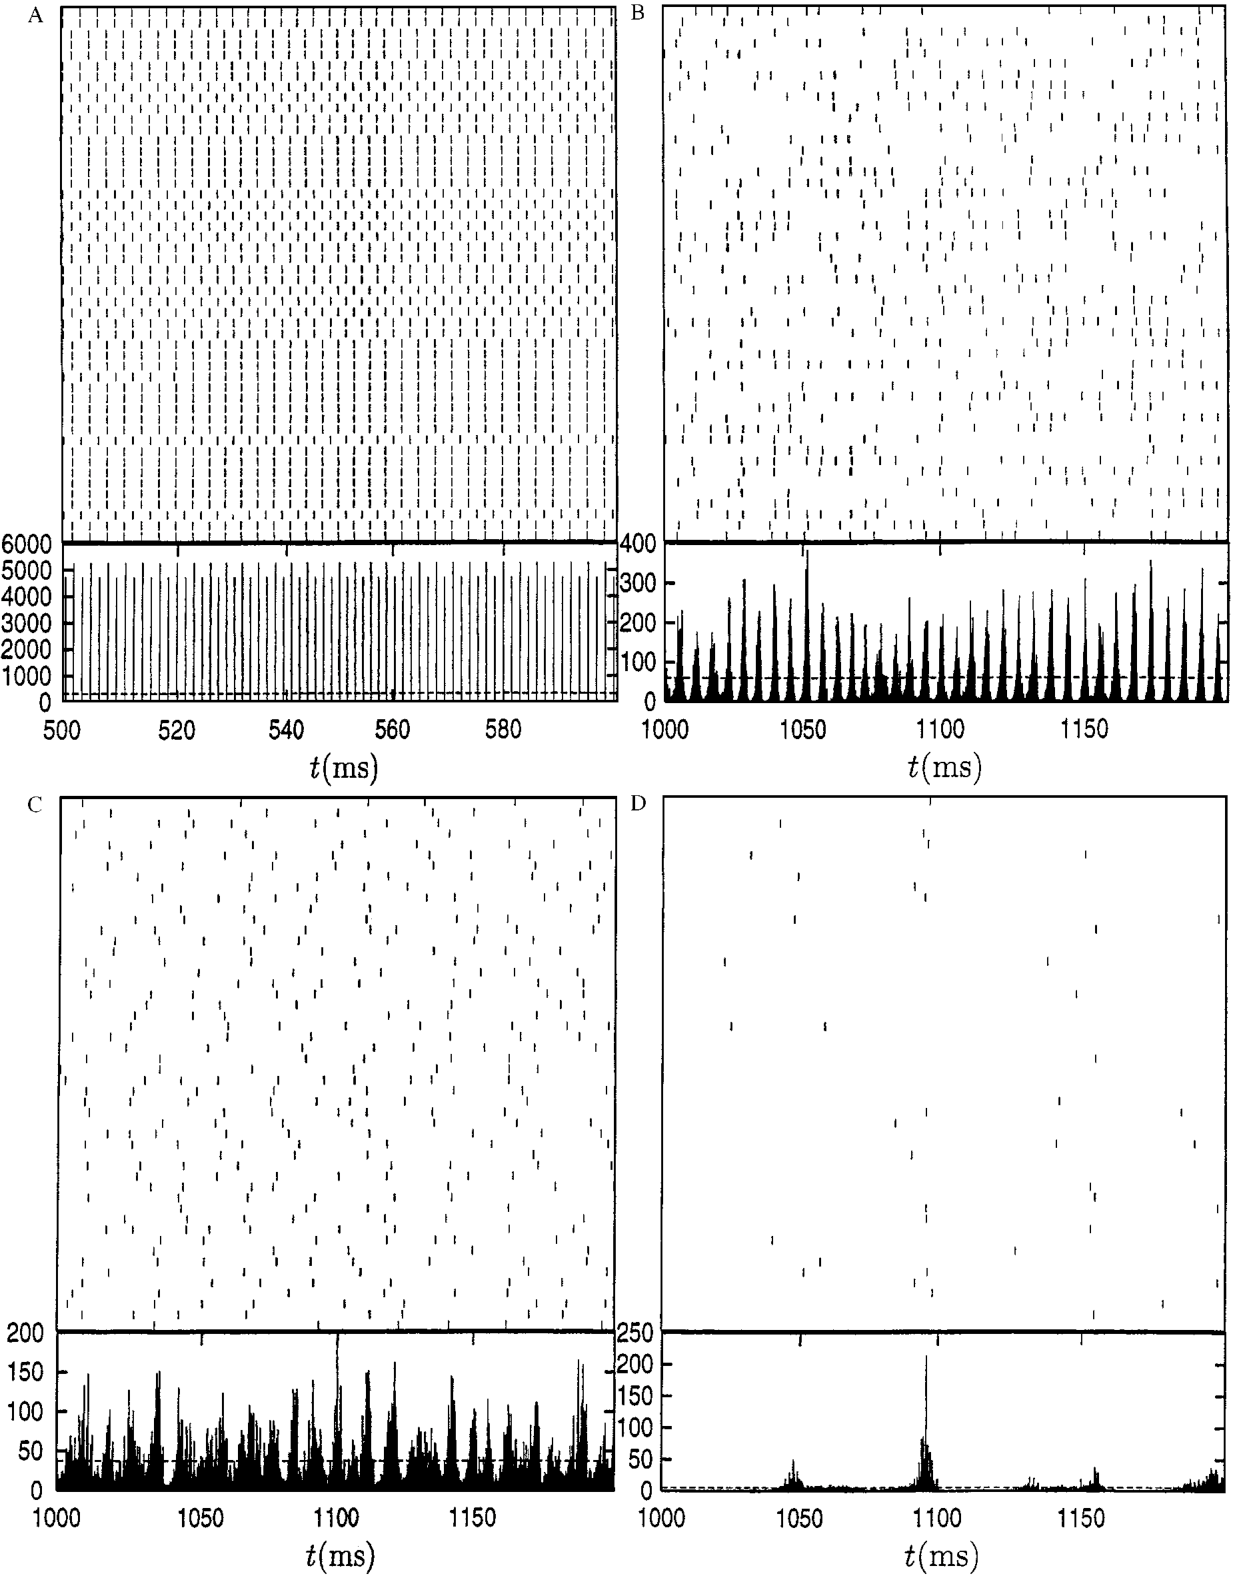</center>

This is the phase diagram of the network showing which parameters lead to a certain regime (Brunel 2000, Fig. 8).

<center>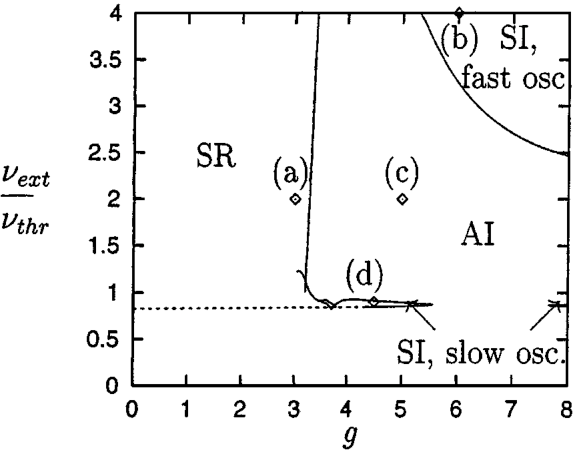</center>

Try to obtain all four dynamical regimes in the simulation.

## Acknowledgements

Contents of this tutorial were based on a NEST-GPU showcase tutorial created by José Villamar, Luca Sergi, G. Tiddia, Pooja Babu, A. Lonardo, F. Simula, L. Pontisso, E. Pastorelli, P.S. Paolucci, B. Golosio and J. Senk. We also thank Hans Ekkehard Plesser for creating tutorial materials.

This software was developed in part or in whole in the Human Brain Project, funded from the European Union’s Horizon 2020 Framework Programme for Research and Innovation under Specific Grant Agreements No. 720270, No. 785907 and No. 945539 (Human Brain Project SGA1, SGA2 and SGA3).

This project has received funding from the European Union’s Horizon Europe Programme under the Specific Grant Agreement No. 101147319 (EBRAINS 2.0 Project).

## Copyright

This file is part of NEST.

Copyright (C) 2004 The NEST Initiative

NEST is free software: you can redistribute it and/or modify it under the terms of the GNU General Public License as published by the Free Software Foundation, either version 2 of the License, or (at your option) any later version.

NEST is distributed in the hope that it will be useful, but WITHOUT ANY WARRANTY; without even the implied warranty of MERCHANTABILITY or FITNESS FOR A PARTICULAR PURPOSE. See the GNU General Public License for more details.

You should have received a copy of the GNU General Public License along with NEST. If not, see http://www.gnu.org/licenses/.